In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt

In [19]:
video = cv2.VideoCapture('data/video_of_finger.MOV')

fps = video.get(cv2.CAP_PROP_FPS)
frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

print(f"Frames per second: {fps:.2f}")
print(f"Total number of frames: {frames:.0f}")
print(f"Duration of video (seconds): {frames / fps:.2f}")

mean_gray = []

while True:
    ret, frame = video.read()
    if not ret:
        break

    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    mean_gray.append(np.mean(gray_frame))

video.release()

print(f"Frames processed: {len(mean_gray)}")

Frames per second: 29.98
Total number of frames: 1852
Duration of video (seconds): 61.78
Frames processed: 1852


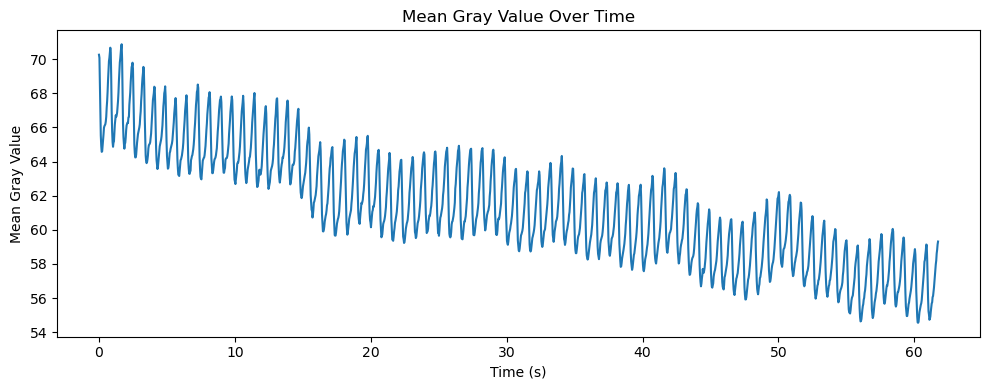

In [20]:
time = np.arange(len(mean_gray)) / fps

plt.figure(figsize=(10, 4))
plt.plot(time, mean_gray)
plt.xlabel("Time (s)")
plt.ylabel("Mean Gray Value")
plt.title("Mean Gray Value Over Time")
plt.tight_layout()
plt.show()

In [21]:
def estimate_hr(signal, fs, bpm_range=(40, 200), filter_order=3):
    x = np.asarray(signal, dtype=float)
    low_bpm, high_bpm = bpm_range
    low_hz, high_hz = low_bpm / 60, high_bpm / 60
    
    sos = butter(filter_order, [low_hz, high_hz], btype="bandpass", fs=fs, output="sos")
    filtered = sosfiltfilt(sos, x)
    freqs = np.fft.rfftfreq(len(filtered), d=1 / fs)
    spectrum = np.abs(np.fft.rfft(filtered - np.mean(filtered)))
    within_range = (freqs >= low_hz) & (freqs <= high_hz)

    dominant_hz = freqs[within_range][np.argmax(spectrum[within_range])]
    
    return {"bpm_fft": float(dominant_hz * 60),
            "dominant_hz": float(dominant_hz),
            "filtered": filtered, "freqs_hz": freqs, "spectrum": spectrum}

In [22]:
video_results = estimate_hr(mean_gray, fs=fps)
print(f"Estimated Heart Rate (BPM): {video_results['bpm_fft']:.2f}")

Estimated Heart Rate (BPM): 71.87


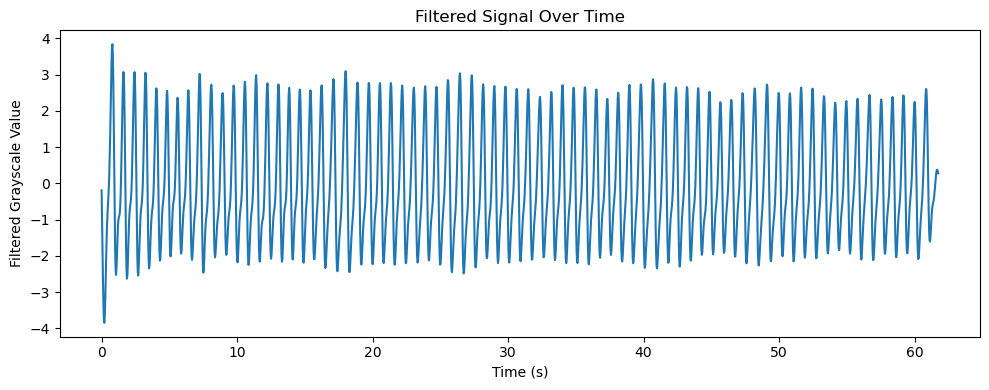

In [23]:
plt.figure(figsize=(10, 4))
plt.plot(time, video_results["filtered"])
plt.xlabel("Time (s)")
plt.ylabel("Filtered Grayscale Value")
plt.title("Filtered Signal Over Time")
plt.tight_layout()
plt.show()

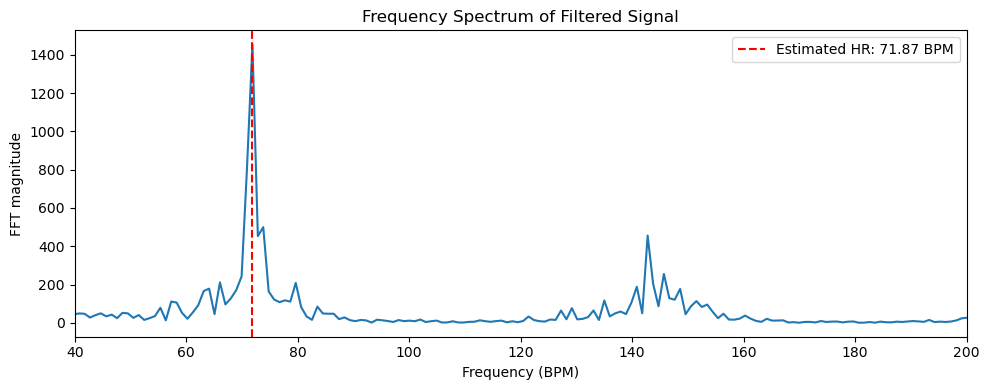

In [24]:
plt.figure(figsize=(10, 4))
plt.plot(video_results["freqs_hz"]*60, video_results["spectrum"])
plt.axvline(video_results["bpm_fft"], color='r', linestyle='--', label=f"Estimated HR: {video_results['bpm_fft']:.2f} BPM")
plt.xlim(40, 200)
plt.xlabel("Frequency (BPM)")
plt.ylabel("FFT magnitude")
plt.title("Frequency Spectrum of Filtered Signal")
plt.legend()
plt.tight_layout()
plt.show()